# 05 — Baseline con regresión logística

Objetivo: establecer un desempeño de referencia para comparar con LightGBM.

- Datos con cierre de seguimiento en 2025.
- Observaciones etiquetadas hasta 2023.
- Clase positiva: abandono.
- Validación: GroupKFold de cinco particiones por estudiante.
- Métricas principales: ROC-AUC y Average Precision.
- Métricas operativas: precisión y recall con umbral inicial de 0,50.

Se utilizan las features y el target ya preparados.

In [16]:
import os 
import sys
from pathlib import Path

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import yaml

from IPython.display import display 
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay
)

#Cambia el directorio de trabajo al root del proyecto
PROJ_ROOT = Path.cwd()
if PROJ_ROOT.name == "notebooks":
        PROJ_ROOT= PROJ_ROOT.parent
assert (PROJ_ROOT/ "src").is_dir()
os.chdir(PROJ_ROOT)

#importar módulos personalizados desde la carpeta src
if str(PROJ_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJ_ROOT))

from src.data.load_data import load_processed, load_raw
from src.features.build_features import matriz_modelado, FEATURES_COLS

#Lee un archivo YAML con parámetros configurables del proyecto
with open("configs/config.yaml", encoding="utf-8") as archivo:
    config = yaml.safe_load(archivo)

#Extrae hiperparametros.
SEED = int(config["random_seed"])
N_SPLITS = int(config["split"]["n_splits"])
UMBRAL = 0.50

print("Proyecto:", PROJ_ROOT)
print("Particiones:", N_SPLITS)


Proyecto: /Users/alejo/Desktop/alerta-temprana-desercion
Particiones: 5


In [17]:
#Modelar el df 
df_modelado = (
    load_processed()
    .sort_values(["id_alumno", "anio_academico"])
    .reset_index(drop=True)
)

#Validaciones 
assert not df_modelado.duplicated(
    ["id_alumno", "anio_academico"]
).any()

assert df_modelado["abandono"].isin([0, 1]).all()
assert df_modelado["id_alumno"].notna().all()
assert set(FEATURES_COLS).issubset(df_modelado.columns)

ultimo_anio_permitido = (
    config["target"]["censurar_hasta"]
    - config["target"]["ventana_anios"]
)

assert df_modelado["anio_academico"].le(
    ultimo_anio_permitido
).all()

In [18]:
print("Dimensiones:", df_modelado.shape)
print("Estudiantes:", df_modelado["id_alumno"].nunique())

distribucion = (
    df_modelado["abandono"]
    .value_counts()
    .sort_index()
    .rename("registros")
    .to_frame()
)

distribucion["porcentaje"] = (
    distribucion["registros"] / len(df_modelado) * 100
).round(2)

display(distribucion)

Dimensiones: (1979, 40)
Estudiantes: 1019


,registros,porcentaje
abandono,,
0.0,1380,69.73
1.0,599,30.27


In [19]:
CLAVES = ["id_alumno", "anio_academico"]

df_raw = load_raw()

edades_originales = df_modelado[CLAVES].merge(
    df_raw[CLAVES + ["edad"]],
    on=CLAVES,
    how="left",
    sort=False,
    validate="one_to_one",
)

assert edades_originales["edad"].notna().all()

pd.testing.assert_frame_equal(
    edades_originales[CLAVES],
    df_modelado[CLAVES],
)

edad_original_invalida = edades_originales["edad"].eq(0)

df_baseline = df_modelado.copy()
df_baseline["edad"] = df_baseline["edad"].astype(float)

df_baseline.loc[edad_original_invalida, "edad"] = np.nan

print(
    "Edades a imputar dentro de cada fold:",
    int(edad_original_invalida.sum()),
)

Edades a imputar dentro de cada fold: 3


In [20]:
X, y, groups = matriz_modelado(df_baseline)

X = X.copy()
y = y.copy()
groups = groups.copy()

#Validar nuestro target y labels
assert not {
    "id_alumno",
    "anio_academico",
    "abandono",
    "prox_actividad",
}.intersection(X.columns)

assert all(
    pd.api.types.is_numeric_dtype(X[col])
    for col in X.columns
)

assert not np.isinf(X.to_numpy(dtype=float)).any()
assert len(X) == len(y) == len(groups)

print("X:", X.shape)
print("y:", y.shape)
print("Estudiantes:", groups.nunique())

display(X.isna().sum().rename("faltantes"))

X: (1979, 13)
y: (1979,)
Estudiantes: 1019


tasa_aprobacion_asignaturas       0
tasa_desaprobacion_asignaturas    0
tasa_ausencias_finales            0
porcentaje_avance_carrera         0
porcentaje_avance_cursado         0
cantidad_pausas                   0
maxima_duracion_pausa             0
antiguedad_carrera                0
edad                              3
delta_tasa_aprobacion             0
brecha_cursado_carrera            0
ritmo_vs_plan                     0
anios_sin_finales                 0
Name: faltantes, dtype: int64

In [21]:
cv = GroupKFold(n_splits=N_SPLITS)

folds = list(cv.split(X, y, groups))

resumen_particiones = []

for fold, (idx_train, idx_valid) in enumerate(folds, start=1):
    alumnos_train = set(groups.iloc[idx_train])
    alumnos_valid = set(groups.iloc[idx_valid])

    assert alumnos_train.isdisjoint(alumnos_valid)
    assert y.iloc[idx_train].nunique() == 2
    assert y.iloc[idx_valid].nunique() == 2

    resumen_particiones.append({
        "fold": fold,
        "registros_train": len(idx_train),
        "registros_valid": len(idx_valid),
        "estudiantes_train": len(alumnos_train),
        "estudiantes_valid": len(alumnos_valid),
        "proporcion_positivos_valid": y.iloc[idx_valid].mean(),
    })

display(pd.DataFrame(resumen_particiones))

,fold,registros_train,registros_valid,estudiantes_train,estudiantes_valid,proporcion_positivos_valid
0,1,1583,396,815,204,0.295455
1,2,1583,396,815,204,0.275253
2,3,1583,396,815,204,0.315657
3,4,1583,396,815,204,0.333333
4,5,1584,395,816,203,0.293671


In [22]:
pipeline_baseline = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("modelo", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=2000,
        class_weight=None,
    )),
])

pipeline_baseline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacion', ...), ('escalado', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto 

In [23]:
probabilidades_oof = np.full(len(X), np.nan)
fold_oof = np.zeros(len(X), dtype=int)
veces_evaluado = np.zeros(len(X), dtype=int)

resultados = []

for fold, (idx_train, idx_valid) in enumerate(folds, start=1):
    modelo_fold = clone(pipeline_baseline)

    modelo_fold.fit(
        X.iloc[idx_train],
        y.iloc[idx_train],
    )

    probabilidades = modelo_fold.predict_proba(
        X.iloc[idx_valid]
    )[:, 1]

    predicciones = (probabilidades >= UMBRAL).astype(int)
    y_valid = y.iloc[idx_valid]

    probabilidades_oof[idx_valid] = probabilidades
    fold_oof[idx_valid] = fold
    veces_evaluado[idx_valid] += 1

    resultados.append({
        "fold": fold,
        "roc_auc": roc_auc_score(y_valid, probabilidades),
        "average_precision": average_precision_score(
            y_valid, probabilidades
        ),
        "precision": precision_score(
            y_valid, predicciones, zero_division=0
        ),
        "recall": recall_score(
            y_valid, predicciones, zero_division=0
        ),
        "proporcion_positivos": y_valid.mean(),
    })

    print(f"Fold {fold} terminado")

assert np.isfinite(probabilidades_oof).all()
assert (veces_evaluado == 1).all()

metricas_folds = pd.DataFrame(resultados)

display(metricas_folds.round(4))

Fold 1 terminado
Fold 2 terminado
Fold 3 terminado
Fold 4 terminado
Fold 5 terminado


,fold,roc_auc,average_precision,precision,recall,proporcion_positivos
0,1,0.8523,0.7034,0.6907,0.5726,0.2955
1,2,0.8291,0.6826,0.6526,0.5688,0.2753
2,3,0.8204,0.7151,0.7041,0.5520,0.3157
3,4,0.8303,0.7511,0.6639,0.5985,0.3333
4,5,0.8082,0.6794,0.6596,0.5345,0.2937


In [24]:
columnas_metricas = [
    "roc_auc",
    "average_precision",
    "precision",
    "recall",
]

resumen_metricas = (
    metricas_folds[columnas_metricas]
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "media",
        "std": "desviacion_estandar",
    })
)

display(resumen_metricas.round(4))

print(f"Proporción global de positivos: {y.mean():.4f}")

,media,desviacion_estandar
roc_auc,0.8281,0.0162
average_precision,0.7063,0.0290
precision,0.6742,0.0221
recall,0.5653,0.0239


Proporción global de positivos: 0.3027


In [25]:
predicciones_oof = df_modelado[CLAVES].copy()

predicciones_oof["abandono_real"] = y.to_numpy()
predicciones_oof["probabilidad_abandono"] = probabilidades_oof
predicciones_oof["prediccion"] = (
    probabilidades_oof >= UMBRAL
).astype(int)

predicciones_oof["fold"] = fold_oof
predicciones_oof["umbral"] = UMBRAL

predicciones_oof["resultado"] = np.select(
    [
        (
            predicciones_oof["abandono_real"].eq(1)
            & predicciones_oof["prediccion"].eq(1)
        ),
        (
            predicciones_oof["abandono_real"].eq(0)
            & predicciones_oof["prediccion"].eq(0)
        ),
        (
            predicciones_oof["abandono_real"].eq(0)
            & predicciones_oof["prediccion"].eq(1)
        ),
    ],
    [
        "verdadero_positivo",
        "verdadero_negativo",
        "falso_positivo",
    ],
    default="falso_negativo",
)

display(predicciones_oof.head(10))

display(
    predicciones_oof["resultado"]
    .value_counts()
    .rename("registros")
)

# Algunos errores para revisar.
display(
    predicciones_oof.loc[
        predicciones_oof["resultado"].isin([
            "falso_positivo",
            "falso_negativo",
        ])
    ].head(10)
)

,id_alumno,anio_academico,abandono_real,probabilidad_abandono,prediccion,fold,umbral,resultado
0,2,2023,1,0.747302,1,4,0.5,verdadero_positivo
1,3,2003,0,0.252353,0,3,0.5,verdadero_negativo
2,3,2004,0,0.449465,0,3,0.5,verdadero_negativo
3,3,2005,1,0.434505,0,3,0.5,falso_negativo
4,4,2008,1,0.759135,1,3,0.5,verdadero_positivo
5,5,2021,1,0.808597,1,2,0.5,verdadero_positivo
6,6,2021,0,0.151279,0,2,0.5,verdadero_negativo
7,6,2022,0,0.099321,0,2,0.5,verdadero_negativo
8,6,2023,0,0.059658,0,2,0.5,verdadero_negativo
9,7,2021,0,0.326820,0,5,0.5,verdadero_negativo


resultado
verdadero_negativo    1216
verdadero_positivo     339
falso_negativo         260
falso_positivo         164
Name: registros, dtype: int64

,id_alumno,anio_academico,abandono_real,probabilidad_abandono,prediccion,fold,umbral,resultado
3,3,2005,1,0.434505,0,3,0.5,falso_negativo
11,8,2003,1,0.381552,0,1,0.5,falso_negativo
17,9,2018,1,0.340351,0,4,0.5,falso_negativo
21,10,2021,1,0.367006,0,1,0.5,falso_negativo
27,12,2006,1,0.087969,0,3,0.5,falso_negativo
30,14,2002,1,0.076417,0,1,0.5,falso_negativo
33,15,2002,0,0.525267,1,1,0.5,falso_positivo
34,15,2003,1,0.478983,0,1,0.5,falso_negativo
37,15,2010,1,0.449890,0,1,0.5,falso_negativo
45,16,2006,1,0.405852,0,1,0.5,falso_negativo


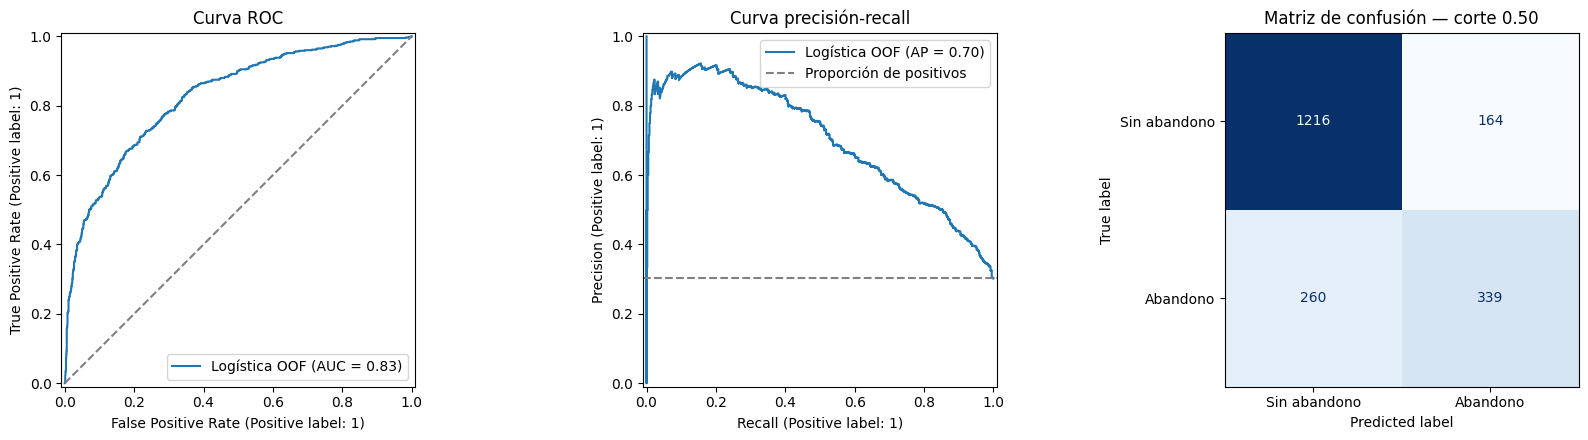

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

RocCurveDisplay.from_predictions(
    y,
    probabilidades_oof,
    name="Logística OOF",
    ax=axes[0],
)

axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC")

PrecisionRecallDisplay.from_predictions(
    y,
    probabilidades_oof,
    name="Logística OOF",
    ax=axes[1],
)

axes[1].axhline(
    y.mean(),
    linestyle="--",
    color="gray",
    label="Proporción de positivos",
)

axes[1].set_title("Curva precisión-recall")
axes[1].legend()

ConfusionMatrixDisplay.from_predictions(
    y,
    predicciones_oof["prediccion"],
    labels=[0, 1],
    display_labels=["Sin abandono", "Abandono"],
    cmap="Blues",
    colorbar=False,
    ax=axes[2],
)

axes[2].set_title(f"Matriz de confusión — corte {UMBRAL:.2f}")

plt.tight_layout()
plt.show()

In [27]:
carpeta_reportes = PROJ_ROOT / "reports"
carpeta_reportes.mkdir(parents=True, exist_ok=True)

metricas_folds.to_csv(
    carpeta_reportes / "metricas_baseline.csv",
    index=False,
)

resumen_metricas.to_csv(
    carpeta_reportes / "resumen_baseline.csv",
    index_label="metrica",
)

predicciones_oof.to_csv(
    carpeta_reportes / "predicciones_baseline_oof.csv",
    index=False,
)

print("Métricas y predicciones de validación guardadas.")

Métricas y predicciones de validación guardadas.


## Resultado del baseline

Se evaluó una regresión logística con imputación y estandarización
ajustadas dentro de cada fold.

Se utilizó GroupKFold con cinco particiones por estudiante.

- ROC-AUC medio: 0.8281
- Desviación estándar ROC-AUC: 0.0162
- Average Precision media: 0.7063
- Desviación estándar Average Precision: 0.0290
- Precisión con umbral 0,50: 0.6742
- Recall con umbral 0,50: 0.5653

Los errores observados fueron: 424

El umbral 0,50 es una referencia inicial, no una banda operativa definitiva.

Esta evaluación mide generalización a estudiantes separados.
Queda pendiente la evaluación temporal.

El siguiente paso es comparar LightGBM utilizando las mismas
observaciones y particiones.